# TP : Prévoir l'inflation américaine avec le chômage et le taux directeur

**Durée estimée :** 2 h 30 · **Niveau :** premier cycle universitaire, bases de Python, de statistique et d'apprentissage automatique

## Objectifs

À la fin de ce TP, vous saurez :

1. identifier le **type d'apprentissage** d'un problème de séries temporelles et justifier ce choix ;
2. charger des séries économiques publiques depuis une URL (FRED) et les explorer graphiquement ;
3. construire une **cible** et des **variables retardées** sans fuite d'information venant du futur ;
4. découper les données **dans le temps** et comparer des modèles par **validation croisée temporelle** ;
5. évaluer un modèle de régression (RMSE, MAE, erreur par période, courbe d'apprentissage) ;
6. répondre à la question posée : **le chômage et le taux directeur aident-ils à prévoir l'inflation ?** ;
7. reconnaître et signaler le **biais d'anticipation** (*look-ahead bias*) propre aux données économiques révisées.

## 1. De quel type d'apprentissage s'agit-il ?

La question est la suivante : **à partir de l'inflation, du chômage et du taux directeur observés aujourd'hui, peut-on prévoir l'inflation d'un an sur l'autre dans 12 mois ?**

Ce problème relève de l'**apprentissage supervisé**, plus précisément de la **régression sur séries temporelles** :

- **Supervisé** : pour chaque date passée, la valeur à prévoir (l'inflation observée 12 mois plus tard) est connue. Le modèle apprend à partir de paires (entrées, sortie).
- **Régression** : la cible est un **nombre réel** (un pourcentage), et non une classe. Dans le TP sur les manchots, la cible était une espèce (classification).
- **Série temporelle** : les observations sont **ordonnées dans le temps** et ne sont pas indépendantes (l'inflation d'un mois ressemble à celle du mois précédent). Trois conséquences importantes :
  1. on **ne mélange pas** les observations pour découper entraînement et test ;
  2. la validation croisée classique est remplacée par une validation qui respecte l'ordre chronologique ;
  3. la référence à battre n'est plus « la classe majoritaire », mais « **demain ressemble à aujourd'hui** » (la dernière valeur).

> **Remarque.** Le chômage et le taux directeur sont ici des **variables explicatives**. La démarche est donc *prédictive* : on cherche à bien prévoir, pas à démontrer qu'une variable *cause* l'inflation.

## 2. Les données

Les données proviennent de **FRED** (*Federal Reserve Economic Data*, banque de la Réserve fédérale de Saint-Louis), accessibles gratuitement par URL.

| Série FRED | Nom dans le TP | Description | Unité |
|---|---|---|---|
| `CPIAUCSL` | `ipc` | Indice des prix à la consommation (tous postes, zone urbaine), désaisonnalisé | indice (base 1982-1984 = 100) |
| `UNRATE` | `chomage` | Taux de chômage, désaisonnalisé | % |
| `FEDFUNDS` | `taux_directeur` | Taux effectif des fonds fédéraux (moyenne mensuelle) | % |

Toutes les séries sont **mensuelles**. Le chargement se fait directement depuis l'URL : une connexion Internet est nécessaire.

In [26]:
# Importation des bibliothèques
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Reproductibilité et style des graphiques
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

def rmse(y_vrai, y_pred):
    # Racine de l'erreur quadratique moyenne, en points de pourcentage
    return float(np.sqrt(mean_squared_error(y_vrai, y_pred)))

In [27]:
# Chargement des trois séries depuis FRED
BASE_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id="
SERIES = {"CPIAUCSL": "ipc", "UNRATE": "chomage", "FEDFUNDS": "taux_directeur"}

def charger_serie(identifiant, nom):
    # Le fichier a deux colonnes : la date (le nom varie selon la version de FRED) et la valeur
    s = pd.read_csv(BASE_URL + identifiant, na_values=".")
    s = s.rename(columns={s.columns[0]: "date", s.columns[1]: nom})
    s["date"] = pd.to_datetime(s["date"])
    return s.set_index("date")[nom]

brut = pd.concat([charger_serie(i, n) for i, n in SERIES.items()], axis=1)
print("Dimensions :", brut.shape)
brut.tail()

Dimensions : (958, 3)


,ipc,chomage,taux_directeur
date,,,
2026-06-01,332.568,4.2,3.63
2026-07-01,332.813,4.1,3.63
2026-08-01,334.131,4.1,3.63
2026-09-01,336.298,4.2,3.75
2026-10-01,NaN,4.1,3.88


## 3. Première exploration

Avant toute modélisation, on examine la structure des données : période couverte par chaque série, valeurs manquantes, statistiques descriptives.

In [28]:
# Début et fin de chaque série, et valeurs manquantes
resume = pd.DataFrame({
    "première date": brut.apply(lambda s: s.first_valid_index()),
    "dernière date": brut.apply(lambda s: s.last_valid_index()),
    "valeurs manquantes": brut.isna().sum(),
})
resume

,première date,dernière date,valeurs manquantes
ipc,1947-01-01,2026-09-01,2
chomage,1948-01-01,2026-10-01,13
taux_directeur,1954-07-01,2026-10-01,90


In [29]:
# Statistiques descriptives
brut.describe().round(2)

,ipc,chomage,taux_directeur
count,956.00,945.00,868.00
mean,125.81,5.65,4.59
std,91.04,1.70,3.52
min,21.48,2.50,0.05
25%,32.89,4.30,1.94
50%,110.30,5.40,4.24
75%,202.82,6.70,6.10
max,336.30,14.80,19.10


**Lecture.** Les trois séries ne démarrent pas à la même date : la plus courte (le taux directeur) fixe le début de l'échantillon utilisable. Les **valeurs manquantes** de début de série sont normales (la série n'existe pas encore). Il peut aussi exister des **mois manquants à l'intérieur** d'une série (par exemple, la publication de l'IPC d'octobre 2025 a été annulée aux États-Unis) : on les repère avec le tableau ci-dessus et on les traite à l'étape suivante.

Les unités diffèrent beaucoup : l'IPC est un indice de plusieurs centaines, alors que le chômage et le taux directeur sont des pourcentages. Cela justifiera une **mise à l'échelle** avant la régression Ridge.

In [30]:
# Mise sur une grille mensuelle régulière et comblement des trous isolés
donnees = brut.asfreq("MS")

# Trous à l'intérieur d'une série : interpolation linéaire, au plus 2 mois consécutifs.
# limit_area="inside" empêche de combler artificiellement la fin de la série.
def trous_interieurs(df):
    # Mois manquants entre la première et la dernière valeur de chaque série
    return {c: int(df[c].loc[df[c].first_valid_index():df[c].last_valid_index()].isna().sum())
            for c in df.columns}

manquants_avant = trous_interieurs(donnees)
donnees = donnees.interpolate(method="linear", limit=2, limit_area="inside")
manquants_apres = trous_interieurs(donnees)

print("Mois manquants à l'intérieur des séries, avant :", manquants_avant)
print("Mois manquants à l'intérieur des séries, après :", manquants_apres)

Mois manquants à l'intérieur des séries, avant : {'ipc': 1, 'chomage': 1, 'taux_directeur': 0}
Mois manquants à l'intérieur des séries, après : {'ipc': 0, 'chomage': 0, 'taux_directeur': 0}


## 4. Visualisation des données

### 4.1 Les séries brutes

On commence par tracer chaque série dans le temps : niveau, tendance, ruptures.

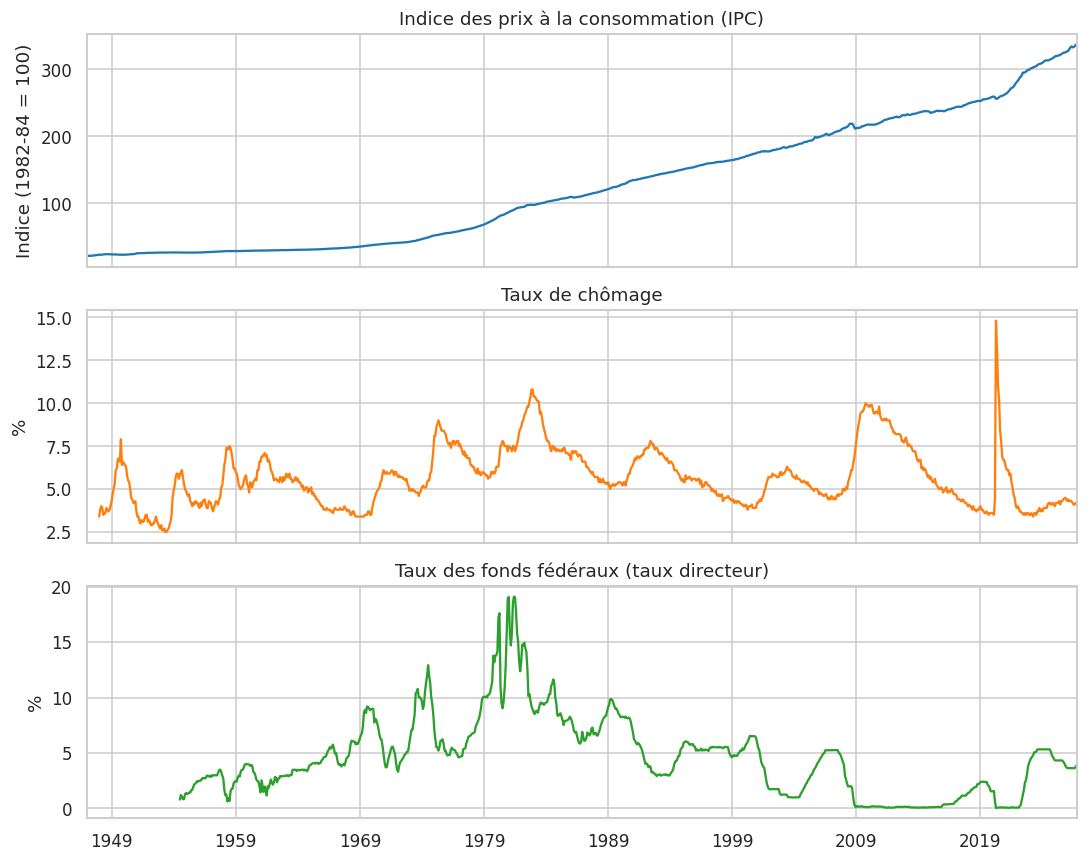

In [31]:
# Les trois séries brutes
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
donnees["ipc"].plot(ax=axes[0], color="tab:blue")
axes[0].set_ylabel("Indice (1982-84 = 100)")
axes[0].set_title("Indice des prix à la consommation (IPC)")

donnees["chomage"].plot(ax=axes[1], color="tab:orange")
axes[1].set_ylabel("%")
axes[1].set_title("Taux de chômage")

donnees["taux_directeur"].plot(ax=axes[2], color="tab:green")
axes[2].set_ylabel("%")
axes[2].set_title("Taux des fonds fédéraux (taux directeur)")
axes[2].set_xlabel("")
plt.tight_layout()
plt.show()

**Lecture.** L'IPC est un **niveau** qui monte presque toujours : il n'est pas directement comparable d'une époque à l'autre. Ce qui nous intéresse est sa **variation**. Le chômage et le taux directeur, eux, oscillent autour d'un niveau et se retournent selon les cycles économiques.

### 4.2 Construire l'inflation

On définit l'**inflation d'un an sur l'autre** comme la variation en pourcentage de l'IPC par rapport au même mois un an plus tôt :

$$\text{inflation}_t = 100 \times \left(\frac{\text{IPC}_t}{\text{IPC}_{t-12}} - 1\right)$$

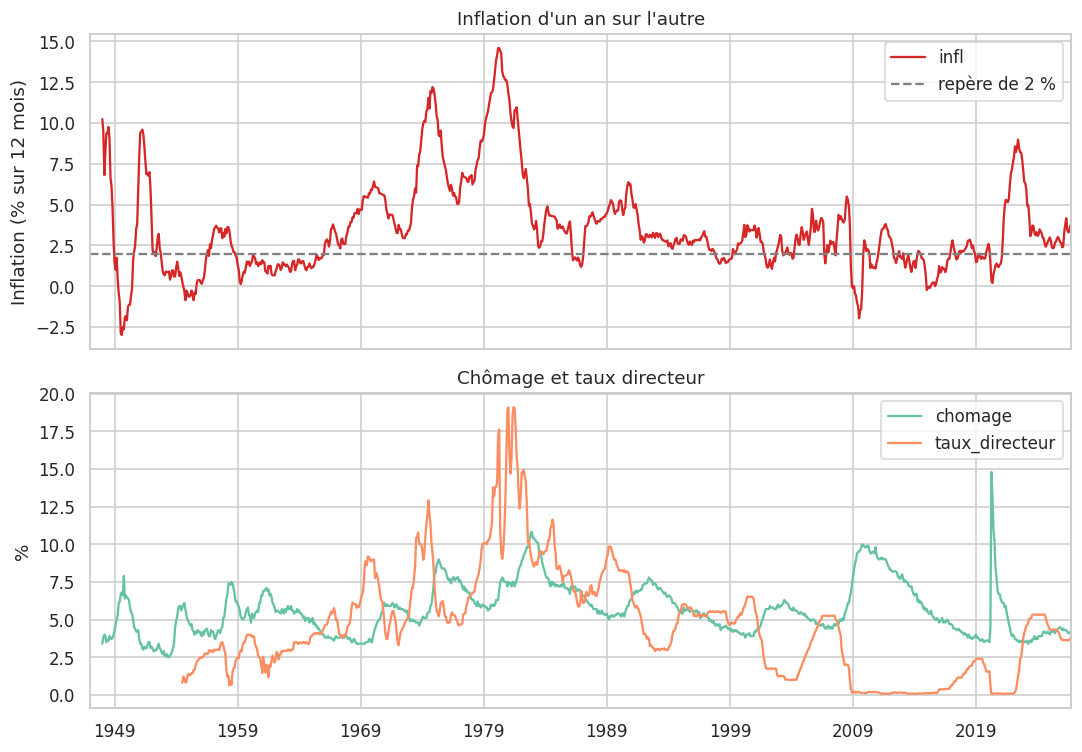

In [7]:
# Variation annuelle de l'indice des prix (en %)
donnees["infl"] = 100 * (donnees["ipc"] / donnees["ipc"].shift(12) - 1)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
donnees["infl"].plot(ax=axes[0], color="tab:red")
axes[0].axhline(2, color="grey", linestyle="--", label="repère de 2 %")
axes[0].set_ylabel("Inflation (% sur 12 mois)")
axes[0].set_title("Inflation d'un an sur l'autre")
axes[0].legend()

donnees[["chomage", "taux_directeur"]].plot(ax=axes[1])
axes[1].set_ylabel("%")
axes[1].set_title("Chômage et taux directeur")
axes[1].set_xlabel("")
plt.tight_layout()
plt.show()

**Lecture.** L'inflation connaît des **régimes** très différents : une période de forte inflation dans les années 1970 et au début des années 1980, une longue période calme, puis un net regain après 2021. Un modèle appris sur une période n'est donc pas forcément valable sur une autre : c'est la difficulté centrale de ce TP. On observe aussi que le taux directeur a tendance à **réagir** à l'inflation (la banque centrale relève ses taux quand les prix montent), ce qui complique l'interprétation des corrélations.

### 4.3 Relation entre l'inflation future et les variables actuelles

Un nuage de points montre si une variable observée aujourd'hui est liée à l'inflation observée **12 mois plus tard**. La couleur indique la décennie.

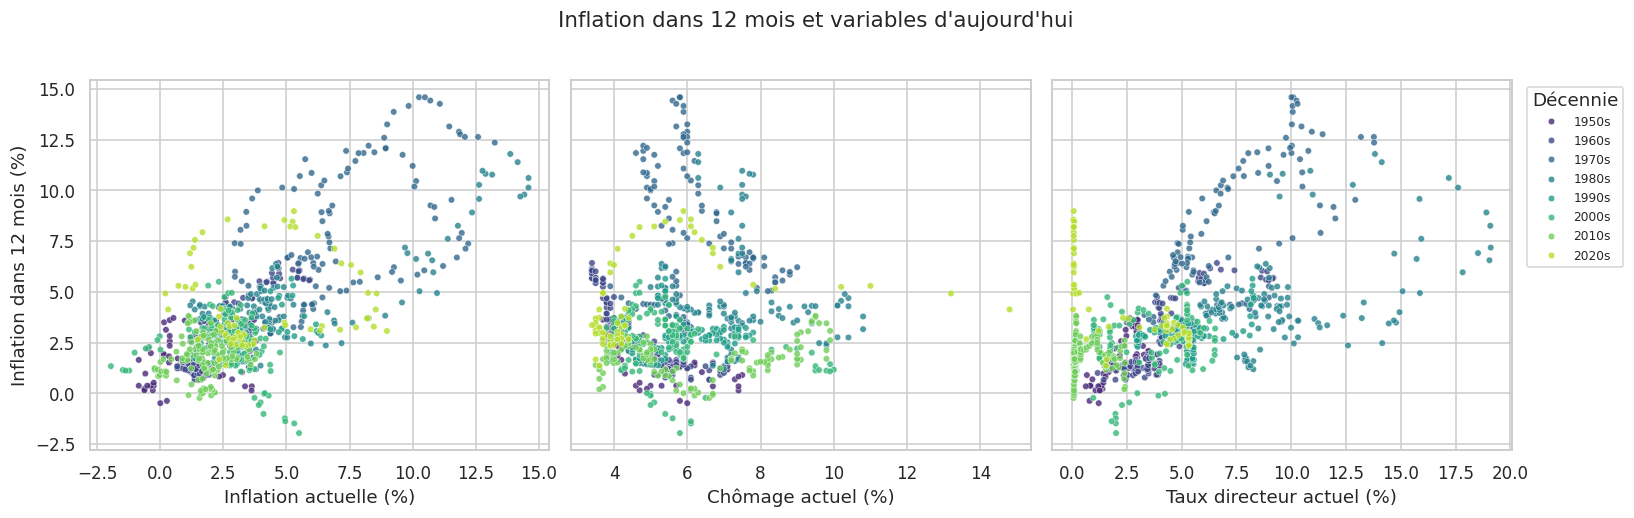

In [8]:
# Inflation dans 12 mois en fonction des variables d'aujourd'hui
tmp = pd.DataFrame({
    "infl_future": donnees["infl"].shift(-12),
    "infl": donnees["infl"],
    "chomage": donnees["chomage"],
    "taux_directeur": donnees["taux_directeur"],
}).dropna()
tmp["decennie"] = (tmp.index.year // 10 * 10).astype(str) + "s"

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
etiquettes = {"infl": "Inflation actuelle (%)",
              "chomage": "Chômage actuel (%)",
              "taux_directeur": "Taux directeur actuel (%)"}
for i, (ax, (var, lab)) in enumerate(zip(axes, etiquettes.items())):
    sns.scatterplot(data=tmp, x=var, y="infl_future", hue="decennie",
                    palette="viridis", s=18, alpha=0.8, ax=ax, legend=(i == 2))
    ax.set_xlabel(lab)
    ax.set_ylabel("Inflation dans 12 mois (%)" if i == 0 else "")
axes[2].legend(title="Décennie", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.suptitle("Inflation dans 12 mois et variables d'aujourd'hui", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Lecture.** L'inflation actuelle est très informative sur l'inflation future : les points sont proches d'une droite. Le chômage et le taux directeur présentent des nuages plus dispersés, dont la forme **change selon la décennie** : la relation n'est pas stable dans le temps. Attention aux conclusions hâtives : deux séries qui évoluent toutes les deux avec le temps peuvent paraître corrélées sans que l'une aide à prévoir l'autre.

### 4.4 Corrélations selon l'horizon

La corrélation entre l'inflation à la date $t+h$ et chaque variable observée en $t$ dépend de l'**horizon** $h$. Le graphique montre jusqu'où chaque variable reste liée à l'inflation future.

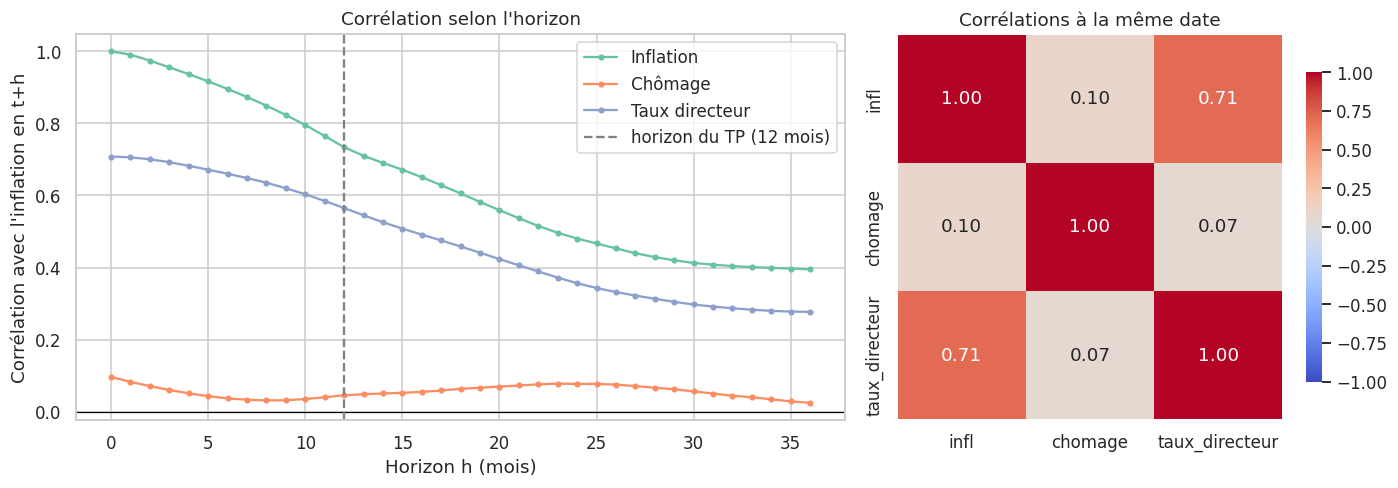

In [9]:
# Corrélation entre la variable en t et l'inflation en t+h, pour h de 0 à 36 mois
d = donnees[["infl", "chomage", "taux_directeur"]].dropna()
horizons = range(0, 37)
corr_h = pd.DataFrame({
    var: [d["infl"].shift(-h).corr(d[var]) for h in horizons]
    for var in ["infl", "chomage", "taux_directeur"]
}, index=list(horizons))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
corr_h.rename(columns={"infl": "Inflation", "chomage": "Chômage",
                       "taux_directeur": "Taux directeur"}).plot(ax=axes[0], marker="o", markersize=3)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].axvline(12, color="grey", linestyle="--", label="horizon du TP (12 mois)")
axes[0].set_xlabel("Horizon h (mois)")
axes[0].set_ylabel("Corrélation avec l'inflation en t+h")
axes[0].set_title("Corrélation selon l'horizon")
axes[0].legend()

corr = d.corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=axes[1])
axes[1].set_title("Corrélations à la même date")
plt.tight_layout()
plt.show()

**Lecture.** La corrélation de l'inflation avec elle-même décroît lentement quand l'horizon augmente : l'inflation est **persistante**. C'est ce qui rend la référence « dernière valeur » difficile à battre. Les corrélations du chômage et du taux directeur sont plus faibles et peuvent changer de signe : l'effet d'un taux élevé sur les prix n'est pas immédiat. Ces corrélations simples ne tiennent pas compte de la tendance commune des séries ; les modèles ci-dessous diront si ces variables apportent une information **supplémentaire** à celle de l'inflation passée.

## 5. Préparation des données

Règles à respecter :

- **Ne jamais utiliser d'information du futur** pour construire une variable d'entrée. Une variable à la date $t$ ne doit contenir que des données connues en $t$.
- **Construire la cible** : l'inflation observée $h = 12$ mois plus tard, $y_t = \text{inflation}_{t+12}$.
- **Construire des retards** : valeurs passées (3, 6 et 12 mois) et variations sur 12 mois, qui donnent au modèle une idée de la dynamique.
- **Découper dans le temps** : l'entraînement précède le test. Aucun mélange aléatoire.
- **Éviter le chevauchement** : la cible d'une ligne d'entraînement porte sur les 12 mois suivants. Si la dernière ligne d'entraînement est trop proche du test, sa cible « déborde » dans la période de test. On laisse donc un **écart de 12 mois**.
- **Standardiser** : la mise à l'échelle est apprise sur l'entraînement seulement, dans un `Pipeline`.

In [10]:
HORIZON = 12  # nombre de mois à prévoir

def construire_variables(d):
    # Variables d'entrée à la date t, construites uniquement avec des données passées
    X = pd.DataFrame(index=d.index)
    X["infl"] = d["infl"]
    X["infl_3m_ann"] = ((d["ipc"] / d["ipc"].shift(3)) ** 4 - 1) * 100  # dynamique récente
    for k in (3, 6, 12):
        X[f"infl_ret{k}"] = d["infl"].shift(k)
    for var in ("chomage", "taux_directeur"):
        X[var] = d[var]
        for k in (3, 6, 12):
            X[f"{var}_ret{k}"] = d[var].shift(k)
        X[f"{var}_var12"] = d[var] - d[var].shift(12)
    return X

X_tout = construire_variables(donnees)
cible = donnees["infl"].shift(-HORIZON).rename("cible")   # inflation dans 12 mois

jeu = X_tout.join(cible).dropna()
colonnes_X = [c for c in jeu.columns if c != "cible"]
print("Variables d'entrée :", len(colonnes_X))
print("Observations utilisables :", len(jeu),
      "| de", jeu.index.min().strftime("%Y-%m"), "à", jeu.index.max().strftime("%Y-%m"))
jeu.head()

Variables d'entrée : 15
Observations utilisables : 843 | de 1955-07 à 2025-09


,infl,infl_3m_ann,infl_ret3,infl_ret6,infl_ret12,chomage,chomage_ret3,chomage_ret6,chomage_ret12,chomage_var12,taux_directeur,taux_directeur_ret3,taux_directeur_ret6,taux_directeur_ret12,taux_directeur_var12,cible
date,,,,,,,,,,,,,,,,
1955-07-01,-0.372301,-0.447176,-0.260611,-0.631032,0.261292,4.0,4.7,4.9,5.8,-1.8,1.68,1.43,1.39,0.80,0.88,1.980568
1955-08-01,-0.484171,-0.745014,-0.594133,-0.629863,0.000000,4.2,4.3,4.7,6.0,-1.8,1.96,1.43,1.29,1.22,0.74,2.208084
1955-09-01,0.149198,2.113135,-0.853749,-0.519866,-0.297508,4.1,4.2,4.6,6.1,-2.0,2.18,1.64,1.35,1.07,1.11,1.862197
1955-10-01,0.374251,0.899882,-0.372301,-0.260611,-0.853432,4.3,4.0,4.7,5.7,-1.4,2.24,1.68,1.43,0.85,1.39,2.572707
1955-11-01,0.373413,2.416809,-0.484171,-0.594133,-0.260708,4.2,4.2,4.3,5.3,-1.1,2.35,1.96,1.43,0.83,1.52,2.343750


In [11]:
# Découpage temporel avec écart de 12 mois
DATE_COUPURE = pd.Timestamp("2010-01-01")

date_cible = jeu.index + pd.DateOffset(months=HORIZON)   # date à laquelle la cible est observée
masque_train = date_cible < DATE_COUPURE                   # la cible est connue avant la coupure
masque_test = jeu.index >= DATE_COUPURE                    # prévisions faites à partir de la coupure

X_train, y_train = jeu.loc[masque_train, colonnes_X], jeu.loc[masque_train, "cible"]
X_test, y_test = jeu.loc[masque_test, colonnes_X], jeu.loc[masque_test, "cible"]

print(f"Entraînement : {len(X_train)} observations, de {X_train.index.min():%Y-%m} à {X_train.index.max():%Y-%m}")
print(f"Test         : {len(X_test)} observations, de {X_test.index.min():%Y-%m} à {X_test.index.max():%Y-%m}")
print(f"Écart de {HORIZON} mois exclu entre les deux : {(~masque_train & ~masque_test).sum()} observations")

Entraînement : 642 observations, de 1955-07 à 2008-12
Test         : 189 observations, de 2010-01 à 2025-09
Écart de 12 mois exclu entre les deux : 12 observations


**Lecture.** L'entraînement couvre les décennies avant 2010, le test les années suivantes, y compris le **choc inflationniste de 2021-2022** que le modèle n'a jamais vu. C'est volontairement exigeant : en prévision économique, le test réaliste est de prédire une période **postérieure** à l'apprentissage. Les observations situées dans les 12 mois précédant la coupure sont retirées : leur cible aurait « regardé » dans la période de test.

## 6. Entraînement et comparaison de modèles

### 6.1 Principe de la comparaison

Nous comparons quatre approches, de la plus simple à la plus complexe :

1. **Référence « dernière valeur »** : on prévoit que l'inflation dans 12 mois sera égale à l'inflation actuelle. C'est la **référence naturelle** en séries temporelles.
2. **Référence « moyenne historique »** : on prévoit toujours la moyenne de l'entraînement.
3. **Régression Ridge** : régression linéaire régularisée, adaptée aux variables corrélées (nos retards le sont beaucoup).
4. **Gradient boosting** : ensemble d'arbres de petite profondeur, qui capture des effets non linéaires.

L'évaluation utilise une **validation croisée temporelle** (`TimeSeriesSplit`) : à chaque pli, on entraîne sur le passé et on valide sur la période qui suit, jamais l'inverse. Le paramètre `gap=12` laisse un écart de 12 mois pour éviter le chevauchement des cibles. La métrique est la **RMSE** (en points de pourcentage d'inflation), pour laquelle **plus petit est meilleur**.

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat y_i)^2}$$

In [12]:
# Référence « dernière valeur » : prévoit que l'inflation future sera égale à l'inflation actuelle
class DerniereValeur(BaseEstimator, RegressorMixin):
    def fit(self, X, y=None):
        return self
    def predict(self, X):
        return X["infl"].to_numpy()

validation = TimeSeriesSplit(n_splits=5, gap=HORIZON)

# Illustration du découpage temporel : dates de chaque pli
for i, (idx_app, idx_val) in enumerate(validation.split(X_train), start=1):
    print(f"Pli {i} : entraînement {X_train.index[idx_app[0]]:%Y-%m} → {X_train.index[idx_app[-1]]:%Y-%m}"
          f" | validation {X_train.index[idx_val[0]]:%Y-%m} → {X_train.index[idx_val[-1]]:%Y-%m}")

Pli 1 : entraînement 1955-07 → 1963-05 | validation 1964-06 → 1973-04
Pli 2 : entraînement 1955-07 → 1972-04 | validation 1973-05 → 1982-03
Pli 3 : entraînement 1955-07 → 1981-03 | validation 1982-04 → 1991-02
Pli 4 : entraînement 1955-07 → 1990-02 | validation 1991-03 → 2000-01
Pli 5 : entraînement 1955-07 → 1999-01 | validation 2000-02 → 2008-12


### 6.2 Choix du paramètre de régularisation de Ridge

Le paramètre $\alpha$ contrôle la force de la régularisation : plus il est grand, plus les coefficients sont réduits. On le choisit **sur l'entraînement uniquement**, par validation croisée temporelle.

Meilleur alpha : 316  (RMSE de validation : 2.837)


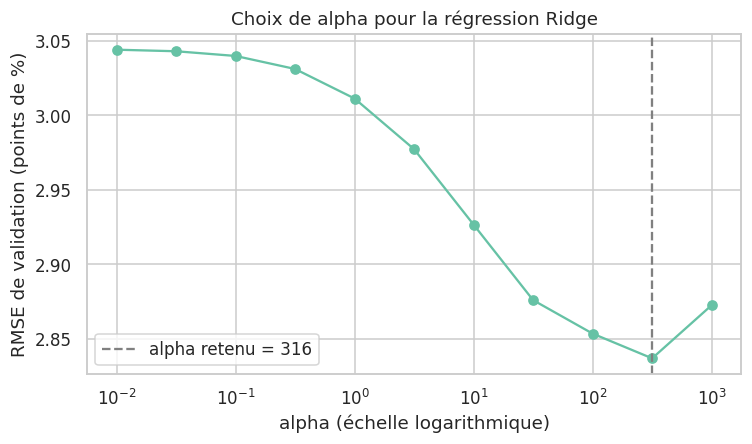

In [13]:
# RMSE en validation croisée temporelle pour plusieurs valeurs de alpha
alphas = np.logspace(-2, 3, 11)
rmse_alpha = []
for a in alphas:
    pipe = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=a))])
    s = -cross_val_score(pipe, X_train, y_train, cv=validation, scoring="neg_root_mean_squared_error")
    rmse_alpha.append(s.mean())

meilleur_alpha = float(alphas[int(np.argmin(rmse_alpha))])
print(f"Meilleur alpha : {meilleur_alpha:.3g}  (RMSE de validation : {min(rmse_alpha):.3f})")

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.semilogx(alphas, rmse_alpha, "o-")
ax.axvline(meilleur_alpha, color="grey", linestyle="--", label=f"alpha retenu = {meilleur_alpha:.3g}")
ax.set_xlabel("alpha (échelle logarithmique)")
ax.set_ylabel("RMSE de validation (points de %)")
ax.set_title("Choix de alpha pour la régression Ridge")
ax.legend()
plt.tight_layout()
plt.show()

**Lecture.** Une valeur très faible de $\alpha$ revient à une régression sans régularisation (risque de surapprentissage quand les variables sont corrélées) ; une valeur très grande écrase les coefficients vers zéro. Le minimum de la courbe indique le meilleur compromis **sur ces données** ; s'il se trouve au bord de la grille, il faut élargir la grille.

### 6.3 Comparaison des quatre approches

In [14]:
# Modèles candidats
modeles = {
    "Référence (dernière valeur)": DerniereValeur(),
    "Référence (moyenne historique)": DummyRegressor(strategy="mean"),
    "Régression Ridge": Pipeline([("scaler", StandardScaler()),
                                  ("ridge", Ridge(alpha=meilleur_alpha))]),
    "Gradient boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.03,
                                                   max_depth=2, subsample=0.8, random_state=42),
}

resultats = []
for nom, modele in modeles.items():
    scores = -cross_val_score(modele, X_train, y_train, cv=validation,
                              scoring="neg_root_mean_squared_error")
    resultats.append({"Modèle": nom, "RMSE moyenne": scores.mean(), "Écart-type": scores.std()})

tableau = pd.DataFrame(resultats).sort_values("RMSE moyenne").reset_index(drop=True)
tableau.round(3)

,Modèle,RMSE moyenne,Écart-type
0,Référence (dernière valeur),1.976,0.788
1,Régression Ridge,2.837,1.360
2,Référence (moyenne historique),3.221,1.839
3,Gradient boosting,3.263,1.353


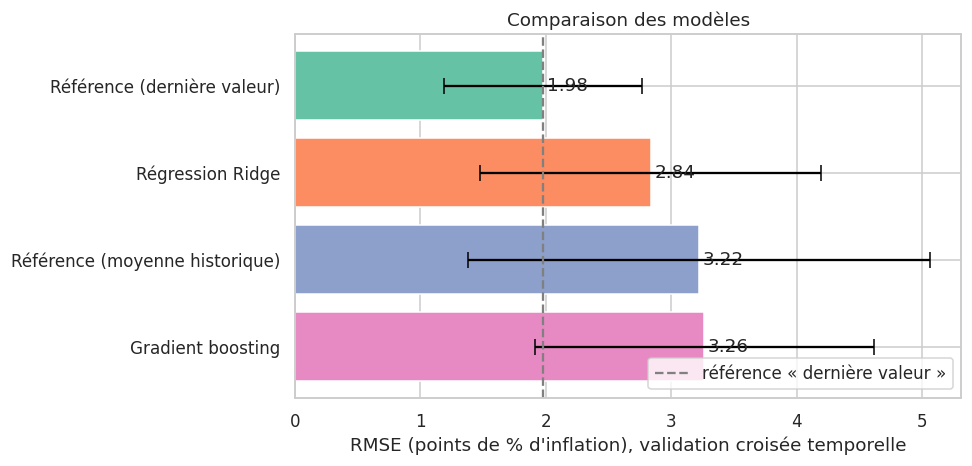

In [15]:
# Graphique : RMSE moyenne en validation croisée temporelle, avec barres d'erreur
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(tableau["Modèle"], tableau["RMSE moyenne"], xerr=tableau["Écart-type"],
        capsize=5, color=sns.color_palette("Set2", len(tableau)))
ax.invert_yaxis()
ref = tableau.loc[tableau["Modèle"] == "Référence (dernière valeur)", "RMSE moyenne"].values[0]
ax.axvline(ref, color="grey", linestyle="--", label="référence « dernière valeur »")
for i, val in enumerate(tableau["RMSE moyenne"]):
    ax.text(val + 0.03, i, f"{val:.2f}", va="center")
ax.set_xlabel("RMSE (points de % d'inflation), validation croisée temporelle")
ax.set_title("Comparaison des modèles")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Lecture.** Comparez chaque modèle appris à la **référence « dernière valeur »** : un modèle qui ne la bat pas n'apporte rien. À 12 mois, cette référence est en général **difficile à battre** car l'inflation est persistante ; les gains, s'il y en a, sont souvent modestes. Regardez aussi les **écarts-types** : ils sont élevés parce que les plis correspondent à des **époques différentes** (inflation forte, puis faible). Un modèle meilleur « en moyenne » mais très variable d'un pli à l'autre est moins fiable qu'un modèle un peu moins bon et stable.

## 7. Évaluation finale sur le jeu de test

On retient le **meilleur modèle appris** (hors références) selon la validation croisée, on l'entraîne sur tout l'ensemble d'entraînement, puis on l'évalue **une seule fois** sur la période de test. On affiche aussi les deux références pour situer le résultat.

Trois métriques sont utilisées :

- la **RMSE**, qui pénalise fortement les grosses erreurs ;
- la **MAE** (erreur absolue moyenne), plus robuste et plus facile à interpréter ;
- le **$R^2$** : part de la variance expliquée. Il peut être **négatif** : le modèle fait alors pire que la moyenne de la période de test.

In [16]:
# Sélection du meilleur modèle appris (hors références) selon la validation croisée
appris = tableau[~tableau["Modèle"].str.startswith("Référence")]
meilleur_nom = appris.iloc[0]["Modèle"]
meilleur_modele = clone(modeles[meilleur_nom]).fit(X_train, y_train)

pred = {
    meilleur_nom: meilleur_modele.predict(X_test),
    "Référence (dernière valeur)": X_test["infl"].to_numpy(),
    "Référence (moyenne historique)": np.full(len(X_test), y_train.mean()),
}

lignes = []
for nom, p in pred.items():
    lignes.append({"Modèle": nom,
                   "RMSE": rmse(y_test, p),
                   "MAE": mean_absolute_error(y_test, p),
                   "R²": r2_score(y_test, p)})
test_tab = pd.DataFrame(lignes).set_index("Modèle")

print("Meilleur modèle appris :", meilleur_nom)
gain = 100 * (1 - test_tab.loc[meilleur_nom, "RMSE"] / test_tab.loc["Référence (dernière valeur)", "RMSE"])
print(f"Variation de la RMSE par rapport à la référence « dernière valeur » : {gain:+.1f} %")
test_tab.round(3)

Meilleur modèle appris : Régression Ridge
Variation de la RMSE par rapport à la référence « dernière valeur » : -11.4 %


,RMSE,MAE,R²
Modèle,,,
Régression Ridge,2.278,1.686,-0.440
Référence (dernière valeur),2.045,1.467,-0.160
Référence (moyenne historique),2.308,2.041,-0.477


**Lecture.** Le signe du gain indique si le modèle fait **mieux (+)** ou **moins bien (−)** que la référence sur la période de test. Sur une période de test qui contient un choc très différent de l'entraînement, il est fréquent qu'un modèle appris ne batte pas la persistance : ce résultat **négatif est un résultat valable** et doit être rapporté tel quel. Le $R^2$ de la référence « moyenne » est proche de zéro ou négatif par construction.

### 7.1 Prévisions et réalité dans le temps

On trace, pour chaque date visée, l'inflation réellement observée et les prévisions faites 12 mois plus tôt.

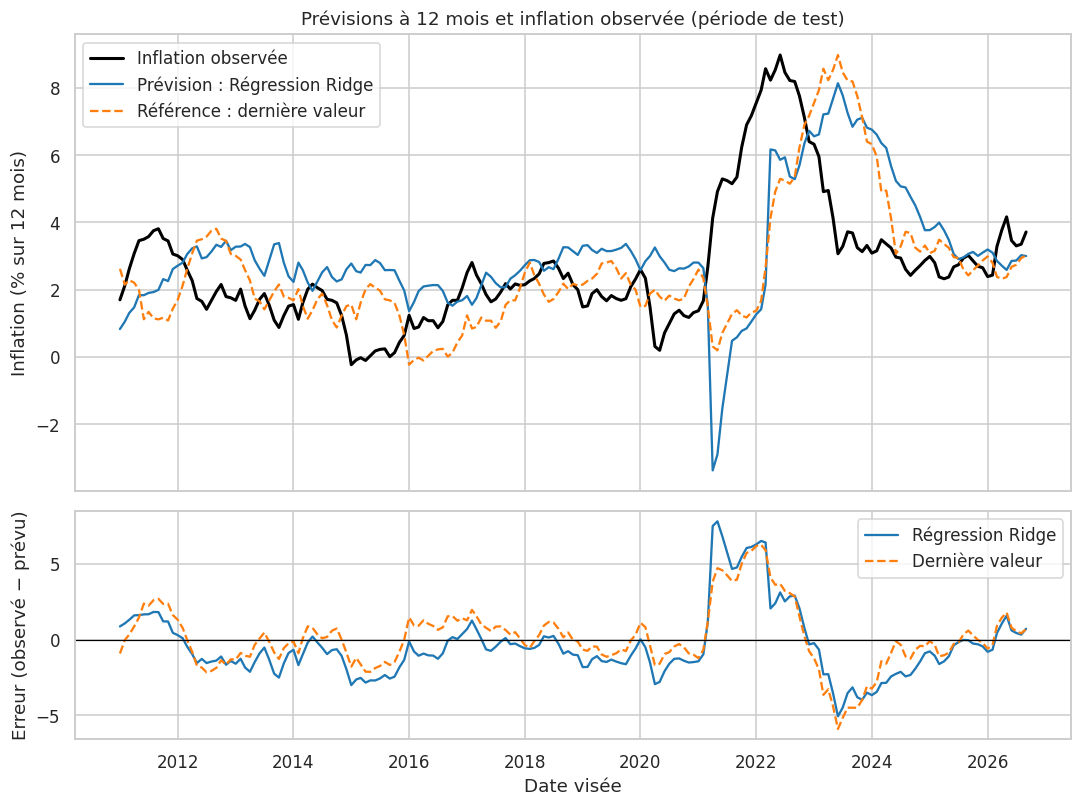

In [17]:
# Inflation observée et prévisions, placées à la date visée (t + 12 mois)
dates_visees = X_test.index + pd.DateOffset(months=HORIZON)

fig, axes = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(dates_visees, y_test.values, color="black", linewidth=2, label="Inflation observée")
axes[0].plot(dates_visees, pred[meilleur_nom], color="tab:blue", label=f"Prévision : {meilleur_nom}")
axes[0].plot(dates_visees, pred["Référence (dernière valeur)"], color="tab:orange",
             linestyle="--", label="Référence : dernière valeur")
axes[0].set_ylabel("Inflation (% sur 12 mois)")
axes[0].set_title("Prévisions à 12 mois et inflation observée (période de test)")
axes[0].legend()

axes[1].plot(dates_visees, y_test.values - pred[meilleur_nom], color="tab:blue", label=meilleur_nom)
axes[1].plot(dates_visees, y_test.values - pred["Référence (dernière valeur)"],
             color="tab:orange", linestyle="--", label="Dernière valeur")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_ylabel("Erreur (observé − prévu)")
axes[1].set_xlabel("Date visée")
axes[1].legend()
plt.tight_layout()
plt.show()

**Lecture.** Les prévisions sont **en retard** sur la réalité : elles suivent les mouvements de l'inflation avec un décalage, surtout pour la référence « dernière valeur », qui est par définition une copie décalée de 12 mois de la série. Les plus grosses erreurs se concentrent sur les **retournements brutaux** (hausse de 2021-2022, puis baisse), que ni le chômage ni le taux directeur observés douze mois plus tôt n'annonçaient clairement.

### 7.2 Erreur selon la période

Une RMSE globale cache des situations très différentes. On la calcule par sous-période de la date visée.

In [18]:
# RMSE par sous-période (selon la date visée)
bornes = pd.to_datetime(["2010-01-01", "2020-01-01", "2023-01-01", "2100-01-01"])
etiquettes_p = ["2011-2019 (inflation basse)", "2020-2022 (choc post-pandémie)", "2023 et après"]
periode = pd.cut(dates_visees, bins=bornes, labels=etiquettes_p, right=False)

df_err = pd.DataFrame({
    "periode": periode,
    "y": y_test.values,
    "meilleur": pred[meilleur_nom],
    "derniere": pred["Référence (dernière valeur)"],
})
lignes = []
for p, g in df_err.groupby("periode", observed=True):
    lignes.append({"Période": p, "Observations": len(g),
                   f"RMSE {meilleur_nom}": rmse(g["y"], g["meilleur"]),
                   "RMSE dernière valeur": rmse(g["y"], g["derniere"])})
par_periode = pd.DataFrame(lignes).set_index("Période")
par_periode.round(3)

,Observations,RMSE Régression Ridge,RMSE dernière valeur
Période,,,
2011-2019 (inflation basse),108,1.362,1.192
2020-2022 (choc post-pandémie),36,3.931,3.334
2023 et après,45,2.233,2.293


**Lecture.** Comparez les colonnes : le modèle peut être meilleur en période calme et moins bon (ou l'inverse) lors du choc. C'est le type de nuance à faire figurer dans le rapport : **une performance moyenne n'a pas de sens si le régime change**.

### 7.3 Courbe d'apprentissage temporelle

Combien d'années de données faut-il au modèle ? On l'entraîne sur les $n$ **premières** observations seulement (fenêtre croissante, en respectant l'ordre du temps), puis on mesure l'erreur sur le test.

- Si l'erreur de test **baisse** quand $n$ augmente, davantage de données aident.
- Si elle se stabilise tôt, ajouter de l'historique n'apporte rien : le modèle est limité par l'information disponible, ou par le changement de régime.

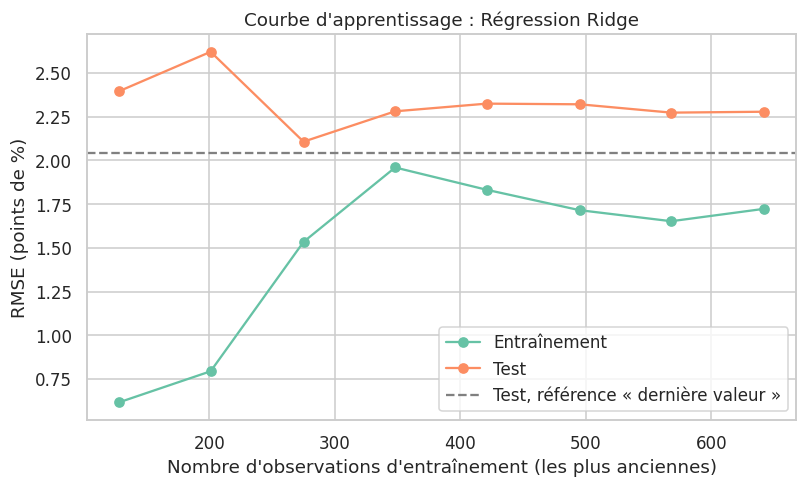

In [19]:
# Courbe d'apprentissage : fenêtre croissante, de 20 % à 100 % de l'entraînement
fractions = np.linspace(0.2, 1.0, 8)
lignes = []
for f in fractions:
    n = int(f * len(X_train))
    m = clone(modeles[meilleur_nom]).fit(X_train.iloc[:n], y_train.iloc[:n])
    lignes.append({"n": n,
                   "Entraînement": rmse(y_train.iloc[:n], m.predict(X_train.iloc[:n])),
                   "Test": rmse(y_test, m.predict(X_test))})
courbe = pd.DataFrame(lignes).set_index("n")

fig, ax = plt.subplots(figsize=(7.5, 4.6))
courbe.plot(ax=ax, marker="o")
ax.axhline(test_tab.loc["Référence (dernière valeur)", "RMSE"], color="grey", linestyle="--",
           label="Test, référence « dernière valeur »")
ax.set_xlabel("Nombre d'observations d'entraînement (les plus anciennes)")
ax.set_ylabel("RMSE (points de %)")
ax.set_title(f"Courbe d'apprentissage : {meilleur_nom}")
ax.legend()
plt.tight_layout()
plt.show()

**Lecture.** Un écart important entre l'erreur d'entraînement (basse) et l'erreur de test (haute) signale un **surapprentissage** ou, ici, un **changement de régime** : ce que le modèle a appris ne s'applique plus aussi bien à la période de test. Comparez la courbe de test à la ligne grise : tant qu'elle reste au-dessus, le modèle ne bat pas la référence.

## 8. Le chômage et le taux directeur aident-ils à prévoir l'inflation ?

C'est la **question de recherche** du TP. Deux outils complémentaires : l'importance des variables, puis une comparaison de jeux de variables (expérience d'ablation).

### 8.1 Importance des variables

L'**importance par permutation** mesure de combien l'erreur augmente sur le jeu de test quand on **mélange** aléatoirement les valeurs d'une variable. Plus l'augmentation est forte, plus le modèle s'appuyait sur cette variable. Elle est préférable à l'importance « de Gini » des arbres, qui est biaisée quand les variables sont corrélées.

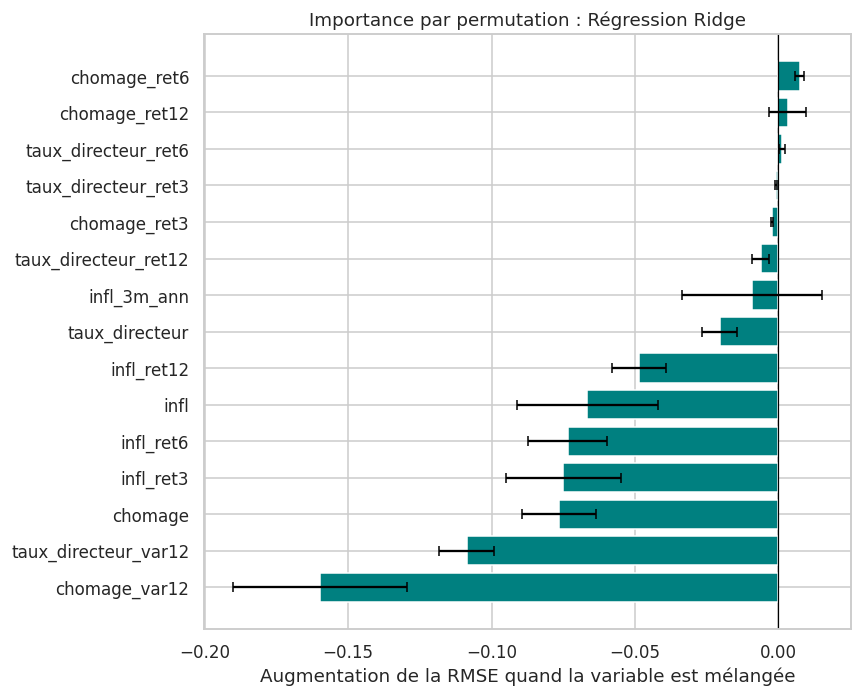

In [20]:
# Importance par permutation sur le jeu de test
imp = permutation_importance(meilleur_modele, X_test, y_test, n_repeats=20, random_state=42,
                             scoring="neg_root_mean_squared_error")
importances = pd.DataFrame({"moyenne": imp.importances_mean, "ecart": imp.importances_std},
                           index=colonnes_X).sort_values("moyenne")

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(importances.index, importances["moyenne"], xerr=importances["ecart"],
        color="teal", capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Augmentation de la RMSE quand la variable est mélangée")
ax.set_title(f"Importance par permutation : {meilleur_nom}")
plt.tight_layout()
plt.show()

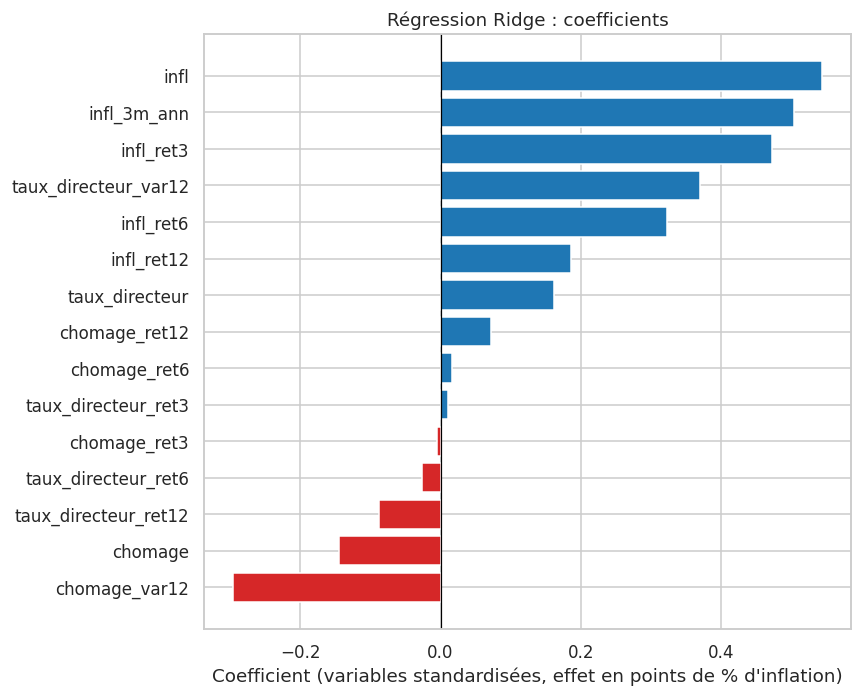

In [21]:
# Coefficients standardisés de la régression Ridge (variables mises à l'échelle)
ridge = clone(modeles["Régression Ridge"]).fit(X_train, y_train)
coefs = pd.Series(ridge.named_steps["ridge"].coef_, index=colonnes_X).sort_values()

fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(coefs.index, coefs.values,
        color=["tab:red" if v < 0 else "tab:blue" for v in coefs.values])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coefficient (variables standardisées, effet en points de % d'inflation)")
ax.set_title("Régression Ridge : coefficients")
plt.tight_layout()
plt.show()

**Lecture.** Les variables d'**inflation** (actuelle, retardée, tendance récente) dominent en général. Les variables liées au chômage et au taux directeur ont une importance plus faible. Deux précautions pour l'interprétation :

- les variables sont **corrélées entre elles** (un retard de 3 mois ressemble au niveau actuel) : l'importance se répartit entre elles et peut paraître faible alors que le groupe est utile ;
- une importance élevée mesure l'usage **par le modèle**, pas une relation de cause à effet.

### 8.2 Expérience d'ablation : que se passe-t-il quand on retire des variables ?

Pour répondre directement à la question, on refait la comparaison avec quatre jeux de variables : l'inflation seule, puis avec le chômage, avec le taux directeur, et avec tout. Si ajouter une variable ne diminue pas l'erreur, elle n'aide pas à prévoir.

In [22]:
# Ablation : quatre jeux de variables, deux modèles
cols_infl = [c for c in colonnes_X if c.startswith("infl")]
cols_chom = [c for c in colonnes_X if c.startswith("chomage")]
cols_taux = [c for c in colonnes_X if c.startswith("taux_directeur")]
ensembles = {
    "Inflation seule": cols_infl,
    "+ chômage": cols_infl + cols_chom,
    "+ taux directeur": cols_infl + cols_taux,
    "Toutes les variables": colonnes_X,
}

lignes = []
for nom_modele in ["Régression Ridge", "Gradient boosting"]:
    for nom_ens, cols in ensembles.items():
        m = clone(modeles[nom_modele])
        cv = -cross_val_score(m, X_train[cols], y_train, cv=validation,
                              scoring="neg_root_mean_squared_error").mean()
        m.fit(X_train[cols], y_train)
        lignes.append({"Modèle": nom_modele, "Variables": nom_ens,
                       "RMSE validation croisée": cv,
                       "RMSE test": rmse(y_test, m.predict(X_test[cols]))})
ablation = pd.DataFrame(lignes)
print("Référence « dernière valeur » : validation croisée",
      round(float(tableau.loc[tableau['Modèle'] == 'Référence (dernière valeur)', 'RMSE moyenne'].iloc[0]), 3),
      "| test", round(float(test_tab.loc['Référence (dernière valeur)', 'RMSE']), 3))
ablation.round(3)

Référence « dernière valeur » : validation croisée 1.976 | test 2.045


,Modèle,Variables,RMSE validation croisée,RMSE test
0,Régression Ridge,Inflation seule,2.491,1.789
1,Régression Ridge,+ chômage,2.703,2.450
2,Régression Ridge,+ taux directeur,2.518,1.987
3,Régression Ridge,Toutes les variables,2.837,2.278
4,Gradient boosting,Inflation seule,3.049,2.305
5,Gradient boosting,+ chômage,2.897,2.738
6,Gradient boosting,+ taux directeur,2.862,2.536
7,Gradient boosting,Toutes les variables,3.263,2.597


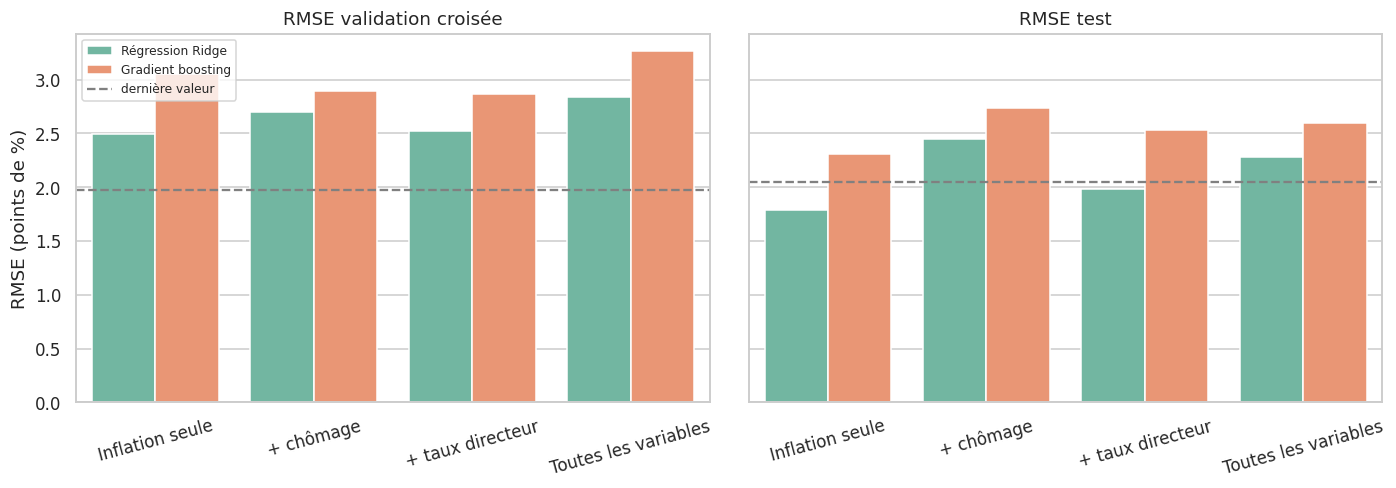

In [23]:
# Graphique de l'ablation
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, col in zip(axes, ["RMSE validation croisée", "RMSE test"]):
    sns.barplot(data=ablation, x="Variables", y=col, hue="Modèle", ax=ax)
    ax.axhline(
        tableau.loc[tableau["Modèle"] == "Référence (dernière valeur)", "RMSE moyenne"].iloc[0]
        if col.startswith("RMSE validation") else test_tab.loc["Référence (dernière valeur)", "RMSE"],
        color="grey", linestyle="--", label="dernière valeur")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=15)
axes[0].set_ylabel("RMSE (points de %)")
axes[1].legend_.remove()
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lecture.** Comparez, pour chaque modèle, la ligne « Inflation seule » aux autres lignes :

- si l'erreur **baisse** en ajoutant le chômage ou le taux directeur, la variable apporte une information utile ;
- si elle **reste égale ou augmente**, elle n'aide pas (ou ajoute du bruit) ;
- la conclusion doit être **cohérente entre validation croisée et test** : un gain visible sur un seul des deux est fragile.

Réponse à rédiger dans le rapport, avec **vos chiffres** : « Sur la période testée, l'ajout du chômage / du taux directeur (réduit / ne réduit pas) la RMSE de X points de pourcentage par rapport à l'inflation seule. »

> **Remarque.** Ne confondez pas « aide à prévoir » et « cause ». Le taux directeur est lui-même fixé en réaction à l'inflation et au chômage : il contient de l'information sur ce que la banque centrale **anticipe**.

## 9. Le biais d'anticipation (*look-ahead bias*)

**À signaler dans le rapport.** Les séries économiques sont **révisées après leur première publication**. Les valeurs téléchargées aujourd'hui ne sont donc pas celles dont disposaient les prévisionnistes à l'époque :

- `CPIAUCSL` est **désaisonnalisé** : les facteurs saisonniers sont réestimés chaque année, ce qui modifie les valeurs passées ;
- `UNRATE` est également désaisonnalisé et révisé ;
- `FEDFUNDS` est une moyenne observée, très peu révisée ;
- les données sont publiées **avec un délai** (l'IPC d'un mois sort environ à la mi-mois suivant) : en date $t$, la valeur de $t$ n'est pas encore connue.

Conséquence : les performances mesurées ici sont **optimistes** par rapport à une vraie prévision en temps réel, car le modèle s'appuie sur des données « propres » qui n'existaient pas encore à la date de la prévision.

**Pistes pour réduire ce biais :**

- utiliser les **millésimes** de données (*vintages*) disponibles sur ALFRED, la base de FRED qui conserve les versions successives (https://alfred.stlouisfed.org) ;
- utiliser des séries **non désaisonnalisées** (par exemple `CPIAUCNS`) ;
- introduire un **délai de publication** dans les variables, comme dans l'expérience ci-dessous.

### 9.1 Mini-expérience : retarder les variables d'un mois

On simule un délai de publication d'un mois : les variables utilisées pour la prévision à la date $t$ sont celles observées en $t-1$. Si les résultats changent peu, l'analyse est robuste à ce point ; sinon, le biais compte.

In [24]:
# Même modèle, mais avec des variables décalées d'un mois (délai de publication)
X_decale = X_tout.shift(1)
jeu_dec = X_decale.join(cible).dropna()
date_cible_dec = jeu_dec.index + pd.DateOffset(months=HORIZON)

tr = date_cible_dec < DATE_COUPURE
te = jeu_dec.index >= DATE_COUPURE
m_dec = clone(modeles[meilleur_nom]).fit(jeu_dec.loc[tr, colonnes_X], jeu_dec.loc[tr, "cible"])
rmse_dec = rmse(jeu_dec.loc[te, "cible"], m_dec.predict(jeu_dec.loc[te, colonnes_X]))
ref_dec = rmse(jeu_dec.loc[te, "cible"], jeu_dec.loc[te, "infl"])

print(f"{meilleur_nom} sans délai : RMSE test = {test_tab.loc[meilleur_nom, 'RMSE']:.3f}")
print(f"{meilleur_nom} avec délai de 1 mois : RMSE test = {rmse_dec:.3f}")
print(f"Référence « dernière valeur » avec délai de 1 mois : RMSE test = {ref_dec:.3f}")

Régression Ridge sans délai : RMSE test = 2.278
Régression Ridge avec délai de 1 mois : RMSE test = 2.386
Référence « dernière valeur » avec délai de 1 mois : RMSE test = 2.130


**Lecture.** Cette expérience ne corrige **pas** les révisions (il faudrait les millésimes d'ALFRED), mais elle montre la sensibilité des résultats à l'information réellement disponible. Mentionnez-la dans la section « limites » du rapport, avec le biais d'anticipation lié aux révisions.

## 10. Prévoir l'inflation dans 12 mois

Une fois le modèle validé, on l'entraîne sur **toutes les données étiquetées** (entraînement et test) et on l'applique aux **dernières données disponibles**, dont on ne connaît pas encore le résultat.

In [25]:
# Prévision pour les dernières données disponibles
X_toutes = jeu[colonnes_X]
y_toutes = jeu["cible"]
modele_final = clone(modeles[meilleur_nom]).fit(X_toutes, y_toutes)

derniere = X_tout[colonnes_X].dropna().iloc[[-1]]
date_info = derniere.index[0]
date_prevue = date_info + pd.DateOffset(months=HORIZON)
prevision = float(modele_final.predict(derniere)[0])
erreur_typique = test_tab.loc[meilleur_nom, "RMSE"]

print(f"Dernières données complètes : {date_info:%Y-%m}")
print(f"Inflation observée à cette date : {derniere['infl'].iloc[0]:.2f} %")
print(f"Prévision pour {date_prevue:%Y-%m} ({meilleur_nom}) : {prevision:.2f} %")
print(f"Ordre de grandeur de l'incertitude (RMSE du test) : ± {erreur_typique:.2f} point de %")

Dernières données complètes : 2026-09
Inflation observée à cette date : 3.72 %
Prévision pour 2027-09 (Régression Ridge) : 3.49 %
Ordre de grandeur de l'incertitude (RMSE du test) : ± 2.28 point de %


**Lecture.** La prévision doit toujours être accompagnée d'un **ordre de grandeur de l'erreur** : ici la RMSE du test, qui est une indication, pas un intervalle de confiance rigoureux. Elle repose sur des données **non encore révisées** pour les mois les plus récents (voir la section 9).

## 11. Synthèse et questions

### Ce qu'il faut retenir

1. **Type d'apprentissage** : supervisé, régression sur séries temporelles. La cible (inflation à 12 mois) est connue pour chaque date passée.
2. **Démarche** : explorer, construire cible et retards sans information du futur, découper **dans le temps** avec un écart, comparer à une référence naturelle, valider par validation croisée temporelle, évaluer une seule fois sur le test.
3. **Référence** : « demain ressemble à aujourd'hui » est exigeante pour l'inflation. Un modèle doit la battre **de façon stable** pour être utile.
4. **Question de recherche** : l'expérience d'ablation permet de dire si le chômage et le taux directeur apportent une information supplémentaire, au-delà de l'inflation passée.
5. **Limites** : changements de régime, révisions des données (biais d'anticipation), différence entre prédiction et causalité.

### Questions

1. Pourquoi mélanger aléatoirement les observations avant de découper entraînement et test serait-il une faute ici ? Quelle information du futur passerait dans l'entraînement ?
2. Modifiez `DATE_COUPURE` (2000-01-01, 2015-01-01). Les conclusions sur le gain par rapport à la référence changent-elles ? Que disent ces changements de la stabilité des résultats ?
3. Modifiez `HORIZON` (3, 6, 12, 24). À quel horizon le chômage et le taux directeur deviennent-ils utiles, le cas échéant ? Reliez ce résultat à la figure 4.4.
4. Retirez le paramètre `gap=HORIZON` de `TimeSeriesSplit`. La RMSE de validation devient-elle plus optimiste ? Expliquez pourquoi.
5. Remplacez le gradient boosting par une forêt aléatoire (`RandomForestRegressor`) puis par `HistGradientBoostingRegressor`. Le classement des modèles change-t-il ?
6. Excluez la période 2020-2023 du test. Le modèle appris bat-il alors la référence ? Que cela signifie-t-il pour la fiabilité du modèle en période de choc ?
7. Rédigez en cinq lignes la section « limites » du rapport en citant le biais d'anticipation et en expliquant l'expérience de la section 9.1.

> **Pour aller plus loin.** Transformez le problème en **classification** : prédire si l'inflation dans 12 mois dépassera 3 %. Quelles métriques utiliseriez-vous (rappel, précision, courbe ROC) ? Pourquoi le déséquilibre entre classes serait-il un problème ?

### Livrable attendu

Ce notebook complété, avec :

- vos réponses aux questions ci-dessus ;
- un court texte d'analyse de l'**importance des variables** (sections 8.1 et 8.2), avec vos chiffres ;
- une section **limites** mentionnant le biais d'anticipation.